# W2 — The weekly global XGBoost

One XGBoost model for all 30,490 series, trained and forecasting on weekly sales (`src/weekly_xgb.py`, Kaggle
jobs in `kaggle_jobs/weekly_xgb/`, all on the CPU). Hyperopt (TPE, 30 trials) tunes each variant on the
validation window 25.04.-22.05.2016 by WRMSSE on weekly sums; the best trial is retrained on the weeks up to
22.05.2016 and forecasts the test window 23.05.-19.06.2016. The tables are written by
`python src/weekly_evaluation.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
import weekly as W
from plot_style import CONTEXT, INK_SECONDARY, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results" / "weekly"
TUNING = ROOT / "results" / "weekly_xgb"
wr = pd.read_csv(RESULTS / "wrmsse.csv")
ORDER = ["01.02.-28.02.2016", "29.02.-27.03.2016", "28.03.-24.04.2016", "25.04.-22.05.2016", "23.05.-19.06.2016"]
LEVELS = ["total", "state", "store", "category", "store x category", "item", "item x store"]

## 1. Tuning

In [2]:
best = {d.name: json.loads((d / "best.json").read_text()) for d in sorted(TUNING.iterdir())}
keys = ["trials", "wrmsse", "mean_rmsse", "rounds", "max_depth", "learning_rate", "min_child_weight", "subsample", "colsample_bytree", "reg_lambda"]
pd.DataFrame({n: {k: b.get(k, b["params"].get(k)) for k in keys} for n, b in best.items()}).T

,trials,wrmsse,mean_rmsse,rounds,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
L_mse,30.000,0.743,0.747,100.000,12.000,0.040,1.100,0.516,0.994,0.245
LE_mse,30.000,0.748,0.756,48.000,6.000,0.123,47.217,0.788,0.957,4.644
LESID_mse,30.000,0.687,0.731,50.000,12.000,0.112,2.045,0.622,0.793,0.339


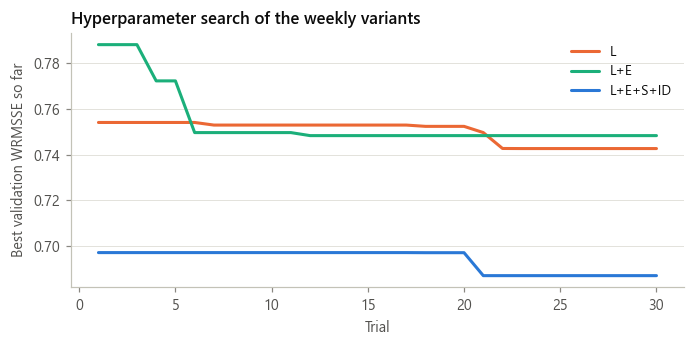

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for (name, color) in zip(["L_mse", "LE_mse", "LESID_mse"], [SERIES[1], SERIES[2], SERIES[0]]):
    t = pd.DataFrame(json.loads((TUNING / name / "trials.json").read_text()))
    ax.plot(t["trial"] + 1, t["wrmsse"].cummin(), color=color, lw=2, label=name.replace("_mse", "").replace("LESID", "L+E+S+ID").replace("LE", "L+E"))
ax.set_xlabel("Trial")
ax.set_ylabel("Best validation WRMSSE so far")
ax.set_title("Hyperparameter search of the weekly variants")
ax.legend()
savefig(fig, "tuning", subdir="weekly")
plt.show()

## 2. Sets of inputs

Validation and test windows; L+E was not run on the earlier windows.

In [4]:
xgb = wr[wr["model"].str.startswith("XGBoost")]
display(xgb.pivot(index="model", columns="window", values="WRMSSE")[ORDER])
xgb[xgb["window"] == ORDER[-1]].set_index("model")[["WRMSSE"] + LEVELS]

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016
model,,,,,
XGBoost L,0.842,0.749,0.650,0.743,0.758
XGBoost L+E,NaN,NaN,NaN,0.748,0.529
XGBoost L+E+S+ID,0.684,0.643,0.561,0.687,0.511
"XGBoost L+E+S+ID, default hyperparameters",0.762,0.662,0.564,0.701,0.575


,WRMSSE,total,state,store,category,store x category,item,item x store
model,,,,,,,,
XGBoost L+E+S+ID,0.511,0.118,0.299,0.443,0.420,0.597,0.847,0.849
XGBoost L,0.758,0.645,0.693,0.696,0.740,0.785,0.879,0.865
XGBoost L+E,0.529,0.144,0.324,0.444,0.448,0.615,0.862,0.870
"XGBoost L+E+S+ID, default hyperparameters",0.575,0.237,0.403,0.533,0.465,0.655,0.866,0.865


On the test window prices and the calendar (group E) carry almost all of the gain over the lags
(0.758 → 0.529), and the statistics and identifiers add a little (0.511). On the validation window it is the
other way round: L+E (0.748) is no better than L (0.743) and the gain comes with S and ID (0.687). With two
windows the contribution of the single groups cannot be separated reliably; the full set is the best on both.

## 3. Seeds

The tuned model (seed 0) and four more seeds with the same hyperparameters.

In [5]:
seeds = pd.read_csv(RESULTS / "seeds.csv")
display(seeds.pivot(index="seed", columns="window", values="WRMSSE")[ORDER[-2:]])
seeds.groupby("window")[["WRMSSE", "total", "item x store", "mean RMSSE per series"]].agg(["mean", "std"]).loc[ORDER[-2:]]

window,25.04.-22.05.2016,23.05.-19.06.2016
seed,,
0,0.687,0.511
1,0.700,0.505
2,0.714,0.509
3,0.718,0.508
4,0.700,0.516


WRMSSE       total       item x store        \
                    mean   std  mean   std         mean   std   
window                                                          
25.04.-22.05.2016  0.704 0.012 0.676 0.022        0.770 0.002   
23.05.-19.06.2016  0.510 0.004 0.103 0.015        0.851 0.001   

                  mean RMSSE per series        
                                   mean   std  
window                                         
25.04.-22.05.2016                 0.730 0.000  
23.05.-19.06.2016                 0.761 0.001

The test result is stable across seeds (0.505-0.516). On the validation window seed 0, on which the
hyperparameters were chosen, is the best of the five (0.687 against 0.700-0.718): its validation score is
slightly optimistic.

## 4. Default hyperparameters

The same inputs with XGBoost's defaults (learning rate 0.3, depth 6, 100 trees), nothing tuned.

In [6]:
pair = wr[wr["model"].isin(["XGBoost L+E+S+ID", "XGBoost L+E+S+ID, default hyperparameters"])]
t = pair.pivot(index="model", columns="window", values="WRMSSE")[ORDER]
t["mean"] = t.mean(axis=1)
t

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016,mean
model,,,,,,
XGBoost L+E+S+ID,0.684,0.643,0.561,0.687,0.511,0.617
"XGBoost L+E+S+ID, default hyperparameters",0.762,0.662,0.564,0.701,0.575,0.653


## 5. Weekly model against weekly sums of the daily main model

In [7]:
pair = wr[wr["model"].isin(["XGBoost L+E+S+ID", "Daily main model, summed to weeks"])]
t = pair.pivot(index="model", columns="window", values="WRMSSE")[ORDER]
t["mean"] = t.mean(axis=1)
display(t)
pair.groupby("model")[LEVELS].mean()

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016,mean
model,,,,,,
"Daily main model, summed to weeks",0.821,0.633,0.522,0.697,0.561,0.647
XGBoost L+E+S+ID,0.684,0.643,0.561,0.687,0.511,0.617


,total,state,store,category,store x category,item,item x store
model,,,,,,,
"Daily main model, summed to weeks",0.458,0.565,0.660,0.578,0.726,0.748,0.793
XGBoost L+E+S+ID,0.399,0.506,0.623,0.521,0.702,0.764,0.803


Neither is consistently better: the weekly model wins in three of the five windows (clearly in
February and on the test window), the summed daily model in two. At the item × store level they are equal.
Training on weekly sums is much cheaper (about 6.6 million training rows instead of about 13 million sampled
daily rows, minutes on a CPU instead of hours on a GPU).